In [1]:
!pip install -q "gymnasium[atari]" ale-py imageio pandas
# https://github.com/Farama-Foundation/Arcade-Learning-Environment
#108 Atari games
# adventure, air_raid, alien, amidar, assault, asterix, asteroids,
# atlantis, atlantis2, backgammon, bank_heist, basic_math, battle_zone,
# beam_rider, berzerk, blackjack, bowling, boxing, breakout, carnival,
# casino, centipede, chopper_command, combat, crazy_climber, crossbow,
#darkchambers, defender, demon_attack, donkey_kong, double_dunk,
# earthworld, elevator_action, enduro, entombed, et, fishing_derby,
# flag_capture, freeway, frogger, frostbite, galaxian, gopher, gravitar,
# hangman, haunted_house, hero, human_cannonball, ice_hockey, jamesbond,
# journey_escape, joust, kaboom, kangaroo, keystone_kapers, king_kong,
# klax, koolaid, krull, kung_fu_master, laser_gates, lost_luggage, mario_bros,
# maze_craze, miniature_golf, montezuma_revenge, mr_do, ms_pacman, name_this_game,
# othello, pacman, phoenix, pitfall, pitfall2, pong, pooyan, private_eye, qbert,
# riverraid, road_runner, robotank, seaquest, sir_lancelot, skiing, solaris,
# space_invaders, space_war, star_gunner, superman, surround, tennis, tetris,
# tic_tac_toe_3d, time_pilot, trondead, turmoil, tutankham, up_n_down, venture,
# video_checkers, video_chess, video_cube, video_pinball, warlords, wizard_of_wor,
# word_zapper, yars_revenge, zaxxon

In [4]:
import re, urllib.request
import numpy as np
import pandas as pd
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

# Google's Dopamine repo ships the standard human / random baselines
# (the Atari-57 numbers from Mnih et al. 2015 / Badia et al. 2020).
URL = ("https://raw.githubusercontent.com/google/dopamine/master/dopamine/labs/atari_100k/normalization_utils.py")
src = urllib.request.urlopen(URL).read().decode()
ns = {} #  empty dictionary
exec(src, ns) #  executes the contents of src using ns as its global namespace
## HUMAN: reference scores achieved by human players
## RANDOM: scores achieved by a random Atari-playing agent
HUMAN, RANDOM = ns["ATARI_HUMAN_SCORES"], ns["ATARI_RANDOM_SCORES"]

# Map the table's keys ("mspacman") to Gymnasium ids ("ALE/MsPacman-v5")
registry = {k.split("/")[1].rsplit("-", 1)[0].lower(): k
            for k in gym.registry if k.startswith("ALE/") and k.endswith("-v5")}

rows = []
for key in sorted(RANDOM):          # RANDOM has all 57 games
    rows.append({
        "game": key,
        "env_id": registry.get(key),
        "random": RANDOM[key],
        "human": HUMAN.get(key, np.nan),
    })
df = pd.DataFrame(rows).set_index("game")
df["human_over_random"] = df["human"] - df["random"]
print(f"{len(df)} games, {df['human'].notna().sum()} with a human score")

def human_normalized(game, score):
    """0 = random play, 1 = the human baseline, >1 = better than the human baseline."""
    r, h = df.loc[game, "random"], df.loc[game, "human"]
    return (score - r) / (h - r)

print(human_normalized("pong", 14.6))      # -> 1.0  (equal to the human baseline)
print(human_normalized("pong", -20.7))     # -> 0.0  (equal to random)


57 games, 55 with a human score
1.0
0.0


In [7]:
def run_random_agent(game_key, episodes=3, max_steps=20_000, seed=0):
    env = gym.make(df.loc[game_key, "env_id"])
    scores = []
    for ep in range(episodes):
        env.reset(seed=seed + ep)
        total, done, steps = 0.0, False, 0
        while not done and steps < max_steps:
            # sample from random actions
            _, r, term, trunc, _ = env.step(env.action_space.sample())
            total += r; steps += 1
            done = term or trunc
        scores.append(total)
    env.close()
    return float(np.mean(scores))
## print for a few games
for g in ["pong", "breakout", "spaceinvaders", "mspacman"]:
    s = run_random_agent(g)
    print(f"{g:14s} random-agent score {s:8.1f} , human {df.loc[g,'human']:9.1f} , human-normalized {human_normalized(g, s):6.3f}")

pong           random-agent score    -21.0 , human      14.6 , human-normalized -0.008
breakout       random-agent score      2.0 , human      30.5 , human-normalized  0.010
spaceinvaders  random-agent score     91.7 , human    1668.7 , human-normalized -0.037
mspacman       random-agent score    253.3 , human    6951.6 , human-normalized -0.008


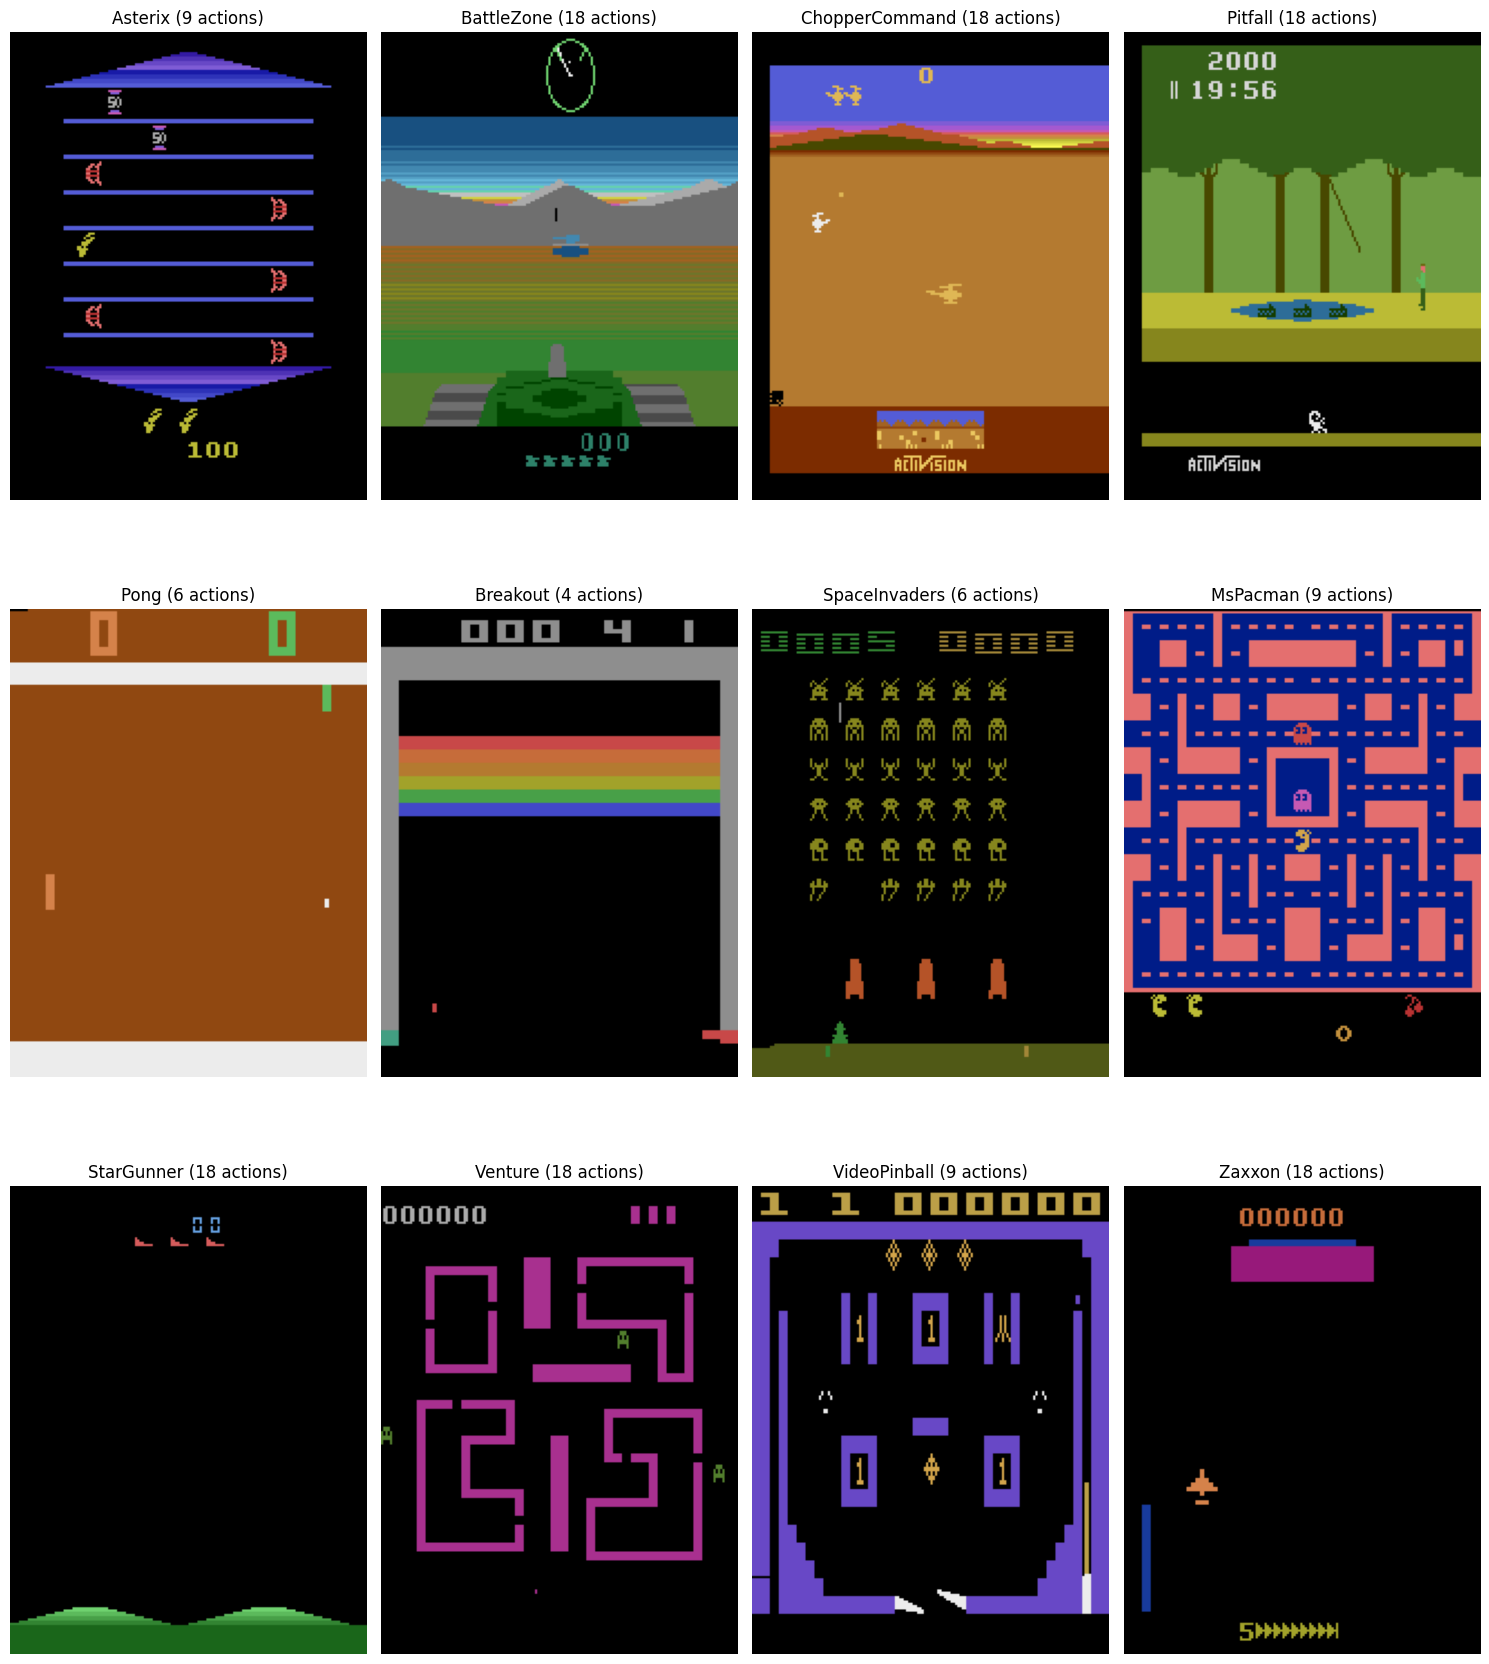

In [9]:
import matplotlib.pyplot as plt
## Plot the images for a few games
games = ["Asterix", "BattleZone", "ChopperCommand", "Pitfall", "Pong", "Breakout", "SpaceInvaders", "MsPacman", "StarGunner", "Venture", "VideoPinball", "Zaxxon"]
fig, axes = plt.subplots(3, 4, figsize=(15, 18))

for ax, game in zip(axes.flat, games):
    env = gym.make(f"ALE/{game}-v5", render_mode="rgb_array")
    env.reset(seed=0)
    for _ in range(60):
        env.step(env.action_space.sample())
    ax.imshow(env.render())
    ax.set_title(f"{game} ({env.action_space.n} actions)")
    ax.axis("off")
    env.close()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(len(games)):
    play_random(games[i], steps=400, every=2, seed=4)